# An introduction to EURADCLIM gridded precipitation observations

**Last updated:** 2026-10-22

[![binder](https://mybinder.org/badge.svg)](https://mybinder.org/v2/gh/TimVlemmixKNMI/c3s-training-submodule-insitu-obs/add-eobs-training-notebook?labpath=eobs_multiple_variables.ipynb)
[![kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/TimVlemmixKNMI/c3s-training-submodule-insitu-obs/blob/add-eobs-training-notebook/eobs_multiple_variables.ipynb)
[![colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TimVlemmixKNMI/c3s-training-submodule-insitu-obs/blob/add-eobs-training-notebook/eobs_multiple_variables.ipynb)

:::{note}
This notebook can be run on free online platforms, such as Binder, Kaggle and Colab, or they can be accessed from GitHub. The links to run this notebook in these environments are provided here, but please note they are not supported by ECMWF.
:::

## EURADCLIM gridded precipitation observations

The EUropean RADar CLIMatology (EURADCLIM) dataset provides high-resolution gridded precipitation observations over Europe. Version 4 covers the period 2013–2025 and provides hourly precipitation accumulations as well as rolling 24-hour precipitation accumulations, both available at every clock-hour, on a 2-km grid. The dataset covers approximately 8 million km², corresponding to about 78% of geographical Europe, and enables the study of precipitation patterns, variability, and extremes at high spatial and temporal resolution.

EURADCLIM is based on precipitation estimates from the European weather radar network, collected through the EUMETNET Operational Program on the Exchange of weather RAdar Information (OPERA). The underlying radar composites provide instantaneous surface rain rates at 15-minute intervals. These observations undergo additional processing to remove non-meteorological echoes and are subsequently merged with precipitation measurements from up to approximately 9,600 rain gauge stations contributing to the European Climate Assessment & Dataset (ECA&D). By combining the spatial coverage of weather radars with the accuracy of rain gauges, EURADCLIM provides a consistent pan-European precipitation dataset.

EURADCLIM complements other European precipitation datasets, such as E-OBS, which provides daily gridded rain gauge observations at a coarser spatial resolution. The higher spatial and temporal resolution of EURADCLIM makes it particularly suitable for investigating localized precipitation events and short-duration rainfall extremes. The dataset is updated annually, with the radar–gauge merging procedure repeated for the complete historical period using the latest available rain gauge observations. EURADCLIM is produced by the Royal Netherlands Meteorological Institute (KNMI) on behalf of the Copernicus Climate Change Service (C3S) and is distributed in NetCDF4 format following CF-1.8 conventions.

This notebook provides an introduction to accessing, visualizing, and analysing EURADCLIM precipitation data using Python. It demonstrates how to use hourly and 24-hour precipitation accumulations and how daily precipitation totals can be reconstructed from consecutive hourly observations.

## Learning objectives 🎯


This Jupyter notebook will help you to work with EURADCLIM gridded precipitation data, which can be obtained via [this page to be replaced_by_final_link](https://cds-dev-cci2.copernicus-climate.eu/datasets/insitu-gridded-observations-euradclim?tab=overview). It will illustrate how to set up an API request and download data files from the Climate Data Store. The second part of the notebook shows how to read the data, produce maps and extract time series.

## Prepare your environment

Before this notebook can be run, a CDS API key needs to be installed on your system, see [how to api](https://cds.climate.copernicus.eu/how-to-api). Depending on your system, you may have to install Cartopy and Xarray.

### (Install and) Import libraries


In [1]:
# Install required libraries
!pip install -q cdsapi

In [2]:
# Import your libraries here
import os
import cdsapi
import zipfile
import xarray as xr
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta
from pathlib import Path
from scipy.spatial import cKDTree
from pyproj import Transformer
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader

### Setup credentials (optional)


The two cells below illustrate how to download EURADCLIM hourly and 24-hour precipitation accumulations using the Climate Data Store (CDS) API and how to specify the output filenames. Note that code snippets for the API requests can be generated on the EURADCLIM dataset download page, which also provides an interface for downloading the data manually.

Note: The EURADCLIM CDS API is not yet fully operational. The API requests below are provided as examples and will be updated when the dataset becomes available through the operational CDS. For the practical exercises in this notebook, the NetCDF files are downloaded directly from the publicly accessible data repository.

In [3]:
# Example CDS API request for EURADCLIM daily precipitation accumulations
# This request is provisional and should not be executed until
# EURADCLIM is available through the operational CDS API.

# Define the CDS dataset and request parameters
dataset = "insitu-gridded-observations-euradclim"

request = {
    "product_type": ["24_hour_accumulation"],
    "year": ["2024"],
    "month": ["03"],
    "day": [
        "01", "02", "03", "04", "05", "06", "07", "08",
        "09", "10", "11", "12", "13", "14", "15", "16",
        "17", "18", "19", "20", "21", "22", "23", "24",
        "25", "26", "27", "28", "29", "30", "31"
    ],
    "time": ["00:00"],
    "version": ["4"],
    "variable": "all"
}

# Define output filename
output_file_24h = "euradclim_24h_202403.zip"

# Uncomment when the CDS API request has been verified:
# client = cdsapi.Client()
# client.retrieve(dataset, request, output_file_24h)

In [4]:
# Example CDS API request for EURADCLIM hourly precipitation accumulations
# This request is provisional and should not be executed until
# EURADCLIM is available through the operational CDS API.

# Define the CDS dataset and request parameters
dataset = "insitu-gridded-observations-euradclim"

request = {
    "product_type": ["1_hour_accumulation"],
    "year": ["2024"],
    "month": ["03"],
    "day": ["01", "02", "03"],
    "time": [
        "00:00", "01:00", "02:00", "03:00",
        "04:00", "05:00", "06:00", "07:00",
        "08:00", "09:00", "10:00", "11:00",
        "12:00", "13:00", "14:00", "15:00",
        "16:00", "17:00", "18:00", "19:00",
        "20:00", "21:00", "22:00", "23:00"
    ],
    "version": ["4"],
    "variable": "all"
}

# Define output filename
output_file_1h = "euradclim_hourly_20240301_03.zip"

# Download data using the CDS API
# Uncomment when the EURADCLIM CDS API becomes operational
# client = cdsapi.Client()
# client.retrieve(dataset, request).download(target=output_file_1h)

The downloaded EURADCLIM data are provided as ZIP archives containing NetCDF files. The following cell extracts both archives into the euradclim_data subdirectory.

In [6]:
with zipfile.ZipFile(output_file_1h, "r") as zip_ref:
    zip_ref.extractall("euradclim_data")

with zipfile.ZipFile(output_file_24h, "r") as zip_ref:
    zip_ref.extractall("euradclim_data")

## Reading data into an Xarray Dataset


The following cells demonstrate how to create lists of hourly and 24-hour EURADCLIM data files, open a NetCDF file as an Xarray Dataset, and inspect its metadata.

In [7]:
euradclim_daily_datafiles = sorted(glob.glob("euradclim_data/*24H*.nc"))  # generate list with all EURADCLIM daily datafiles
euradclim_hourly_datafiles = sorted(glob.glob("euradclim_data/*HOURLY*.nc"))  # generate list with all EURADCLIM hourly datafiles

print("first hourly file:", euradclim_hourly_datafiles[0])
print("last hourly file:", euradclim_hourly_datafiles[-1])

print("first daily file:", euradclim_daily_datafiles[0])
print("last daily file:", euradclim_daily_datafiles[-1])

first hourly file: euradclim_data/RAD_OPERA_HOURLY_RAINFALL_ACCUMULATION_202403020000_v4.nc
last hourly file: euradclim_data/RAD_OPERA_HOURLY_RAINFALL_ACCUMULATION_202403030000_v4.nc
first daily file: euradclim_data/RAD_OPERA_24H_RAINFALL_ACCUMULATION_202403010000_v4.nc
last daily file: euradclim_data/RAD_OPERA_24H_RAINFALL_ACCUMULATION_202403310000_v4.nc


In [8]:
ds = xr.open_dataset(euradclim_hourly_datafiles[0])
ds.info()

xarray.Dataset {
dimensions:
	t = 1 ;
	y = 1900 ;
	x = 2200 ;

variables:
	datetime64[ns] time(t) ;
		time:standard_name = time ;
	float32 precipitation_amount(t, y, x) ;
		precipitation_amount:IMAGE_VERSION = 1.2  ;
		precipitation_amount:units = kg m-2 ;
		precipitation_amount:standard_name = precipitation_amount ;
		precipitation_amount:grid_mapping = crs ;
	int32 crs() ;
		crs:grid_mapping_name = latitude_longitude ;
		crs:epsg_code = EPSG:4326 ;
		crs:semi_major_axis = 6378137.0 ;
		crs:inverse_flattening = 298.257223563 ;
	float32 lat(y, x) ;
		lat:standard_name = latitude ;
		lat:units = degrees_north ;
	float32 lon(y, x) ;
		lon:standard_name = longitude ;
		lon:units = degrees_east ;

// global attributes:
	:Conventions = CF-1.8 ;
	:history = 2026-07-19T22:04:23.800928+00:00Z: converted from HDF5 to NetCDF4 (CF baseline) ;
	:title = EURADCLIM Gridded Precipitation Data for 2024-03-02 00:00 ;
}

## Further explanation of the dataset structure and practical examples

- The main variable in the dataset is `precipitation_amount`. Its units are kg m⁻², which is numerically equivalent to mm of rainfall.

- The timestamp included in the filename and the time indicated in the global attribute `title` are both consistent with the single value stored in the variable `time`. Converting this value to a Python `datetime` object allows standard time-based operations (see below). Note that the timestamp represents the **end of the accumulation interval**. For hourly data, the start time is one hour earlier; for 24-hour accumulation data, it is 24 hours earlier. For many applications, it is convenient to have both the start and end times of each accumulation interval. This is illustrated below.

- Note that the longitude and latitude variables are two-dimensional, and the curvilinear grid is not aligned with lines of constant latitude and longitude. Further below, we explain how to determine pixel corners and how to identify the grid pixel corresponding to a station location (e.g. a rain gauge).

Here below some examples are given to understand and work with the variable `precipitation_amount`

In [9]:
var_name = "precipitation_amount"
print("attributes:", ds[var_name].attrs) # dictionary with all attributes for the variable precipiration_amount
print("unit:", ds[var_name].units) # direct access to unit

attributes: {'IMAGE_VERSION': '1.2 ', 'units': 'kg m-2', 'standard_name': 'precipitation_amount', 'grid_mapping': 'crs'}
unit: kg m-2


In [10]:
# Find the maximum precipitation value
field = ds[var_name].values
max_value = np.nanmax(field)

# pixel indices of all pixels with this maximum value
max_indices = np.argwhere(field == max_value)
print(max_indices)

[[   0 1181 1651]
 [   0 1181 1652]
 [   0 1182 1650]
 [   0 1182 1651]
 [   0 1182 1652]
 [   0 1182 1654]
 [   0 1183 1652]
 [   0 1183 1653]]


Examples for working with the variable `time` in case of a single file (for more files see below):

In [11]:
time = ds["time"].values[0] # extract time value from dataset object
time_end_dt = time.astype("datetime64[us]").astype(datetime) # conversion of time to datetime object (this is the end time of the accumulation interval)
time_start_dt = time_end_dt-timedelta(hours=1) # determine start time of accumulation interval corresponding to data file

print(time_end_dt.strftime("%Y-%m-%d %H:%M UTC"))
print(time_start_dt.strftime("%Y-%m-%d %H:%M UTC"))

2024-03-02 00:00 UTC
2024-03-01 23:00 UTC


In [12]:
# last 5 files from list of daily EURADCLIM files
for file in euradclim_daily_datafiles[-5:]:
    ds_temp = xr.open_dataset(file)
    print(file,' | ',ds_temp['time'].values[0].astype("datetime64[us]").astype(datetime).strftime("%Y-%m-%d %H:%M UTC"))

euradclim_data/RAD_OPERA_24H_RAINFALL_ACCUMULATION_202403270000_v4.nc  |  2024-03-27 00:00 UTC
euradclim_data/RAD_OPERA_24H_RAINFALL_ACCUMULATION_202403280000_v4.nc  |  2024-03-28 00:00 UTC
euradclim_data/RAD_OPERA_24H_RAINFALL_ACCUMULATION_202403290000_v4.nc  |  2024-03-29 00:00 UTC
euradclim_data/RAD_OPERA_24H_RAINFALL_ACCUMULATION_202403300000_v4.nc  |  2024-03-30 00:00 UTC
euradclim_data/RAD_OPERA_24H_RAINFALL_ACCUMULATION_202403310000_v4.nc  |  2024-03-31 00:00 UTC


The final file in the list has 20240331 in its filename, corresponding to an accumulation interval ending at 00:00 UTC on 31 March 2024. It therefore represents precipitation accumulated during 30 March, rather than 31 March. To obtain the precipitation accumulation for 31 March, the file RAD_OPERA_24H_RAINFALL_ACCUMULATION_202404010000_v4.nc would be required (not included here).

Similarly, the hourly file RAD_OPERA_HOURLY_RAINFALL_ACCUMULATION_202403020000_v4.nc represents precipitation accumulated between 23:00 UTC on 1 March and 00:00 UTC on 2 March 2024.

Structure of spatial grid: working with two dimensional latitude and longitude arrays:

In [13]:
print('Upper Left (NW): ',ds.lat.values[0,0],ds.lon.values[0,0])
print('Lower Left (SW): ',ds.lat.values[0,-1],ds.lon.values[0,-1])
print('Upper Right (NE): ',ds.lat.values[-1,0],ds.lon.values[-1,0])
print('Lower Right (SE): ',ds.lat.values[-1,-1],ds.lon.values[-1,-1])

Upper Left (NW):  67.02246 -39.50293
Lower Left (SW):  31.757812 -10.426758
Upper Right (NE):  67.62012 57.77832
Lower Right (SE):  31.999023 29.413086


Visualisation of spatial grid and precipitation data field:

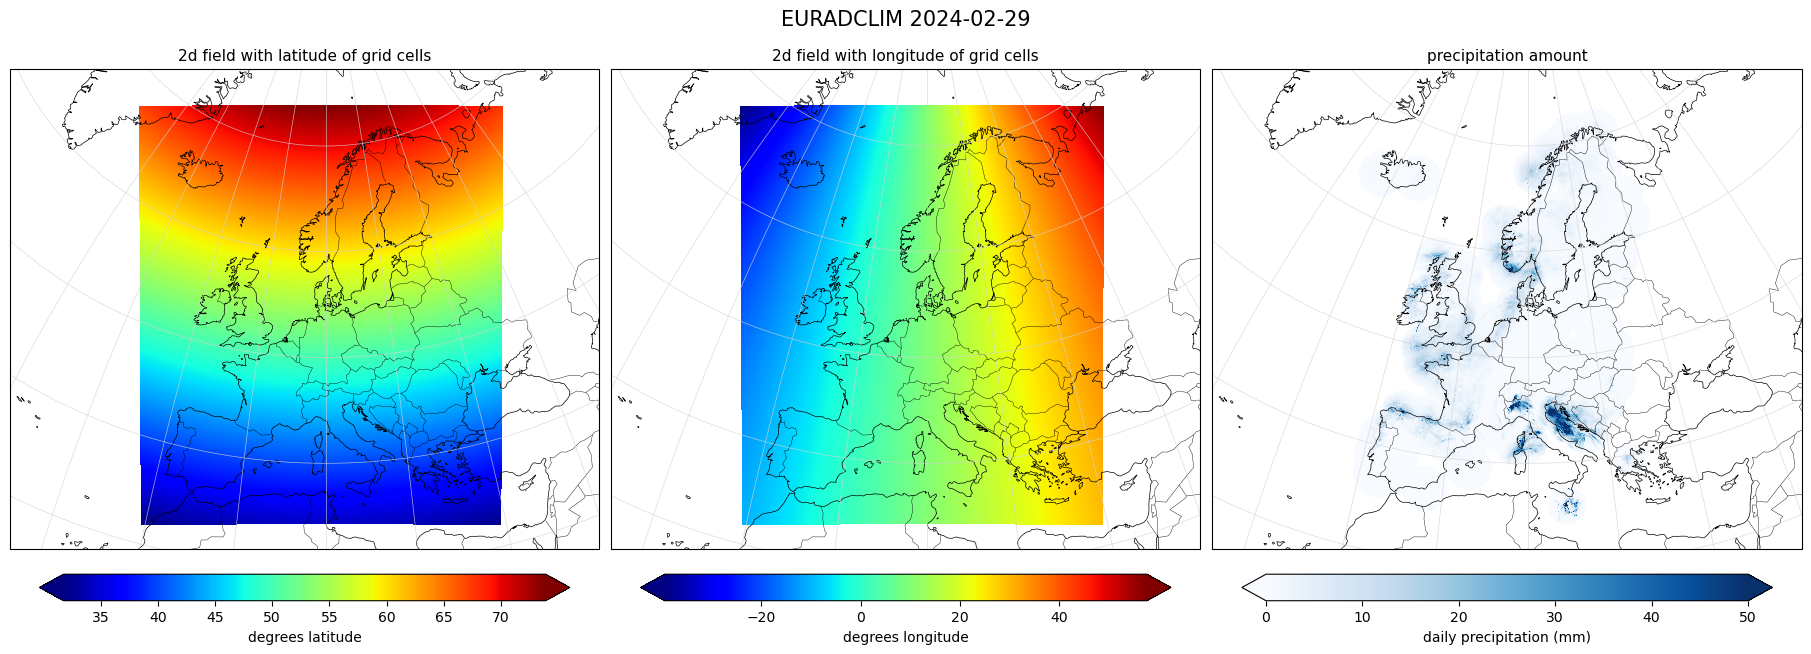

In [14]:
ds = xr.open_dataset(euradclim_daily_datafiles[0])  # open .nc file into Xarray dataset
lon2d, lat2d = ds["lon"].values, ds["lat"].values
precip = ds["precipitation_amount"].values[0,:,:]

time = ds["time"].values[0]
time_end_dt = time.astype("datetime64[us]").astype(datetime)
time_start_dt = time_end_dt - timedelta(hours=24)

fields = [lat2d, lon2d, precip]
titles = ["2d field with latitude of grid cells", "2d field with longitude of grid cells", "precipitation amount"]
cmaps = ["jet", "jet", "Blues"]
vmins = [np.nanmin(lat2d), np.nanmin(lon2d), 0]
vmaxs = [np.nanmax(lat2d), np.nanmax(lon2d), 50]
cbar_labels = ["degrees latitude", "degrees longitude", "daily precipitation (mm)"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6.4), subplot_kw={"projection": ccrs.epsg(3035)}, constrained_layout=True)

for i, (ax, field, title) in enumerate(zip(axes, fields, titles)):
    mesh = ax.pcolormesh(lon2d, lat2d, field, shading="nearest", transform=ccrs.PlateCarree(),
                         cmap=cmaps[i], vmin=vmins[i], vmax=vmaxs[i])

    ax.set_extent([-25, 40, 30, 75], crs=ccrs.PlateCarree())
    ax.coastlines(resolution="50m", linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3)

    # Latitude/longitude grid lines every 10 degrees
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=False, linewidth=0.5,color="lightgrey", 
                      alpha=0.8, linestyle="-",xlocs=np.arange(-30, 51, 10), ylocs=np.arange(30, 81, 10))

    ax.set_title(title, fontsize=11)

    cbar = fig.colorbar(mesh, ax=ax, orientation="horizontal", pad=0.04, shrink=0.9, extend="both")
    cbar.set_label(cbar_labels[i])

fig.suptitle("EURADCLIM %s"%(time_start_dt.strftime("%Y-%m-%d")), fontsize=15)
plt.show()

The EURADCLIM grid is represented by two-dimensional latitude and longitude arrays. Although the grid appears rectangular in the map projection used above, lines of constant grid index do not generally correspond to lines of constant latitude or longitude. This is illustrated below by plotting the geographical coordinates along two lines of constant grid index.

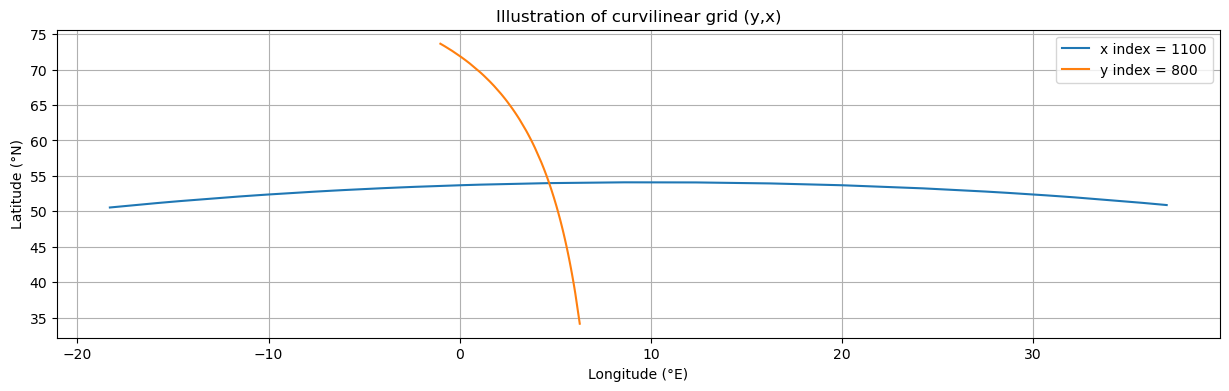

In [15]:
fig, ax = plt.subplots(figsize=(15, 4))
ax.set_title('Illustration of curvilinear grid (y,x)')
ax.plot(ds.lon.values[:,1100], ds.lat.values[:,1100],label='x index = 1100')
ax.plot(ds.lon.values[800,:], ds.lat.values[800,:],label='y index = 800')
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.legend()
ax.grid()

Concatenation of daily and hourly files over time in order to create one dataset for all hourly data and one for all daily data:

In [16]:
ds_hourly = xr.open_mfdataset(euradclim_hourly_datafiles, combine="nested", concat_dim="t", data_vars="minimal", coords="minimal", compat="override")
ds_daily = xr.open_mfdataset(euradclim_daily_datafiles, combine="nested", concat_dim="t", data_vars="minimal", coords="minimal", compat="override")

print(ds_hourly)

<xarray.Dataset> Size: 451MB
Dimensions:               (t: 25, y: 1900, x: 2200)
Coordinates:
    lat                   (y, x) float32 17MB dask.array<chunksize=(950, 1100), meta=np.ndarray>
    lon                   (y, x) float32 17MB dask.array<chunksize=(950, 1100), meta=np.ndarray>
Dimensions without coordinates: t, y, x
Data variables:
    time                  (t) datetime64[ns] 200B dask.array<chunksize=(1,), meta=np.ndarray>
    precipitation_amount  (t, y, x) float32 418MB dask.array<chunksize=(1, 950, 1100), meta=np.ndarray>
    crs                   int32 4B ...
Attributes:
    Conventions:  CF-1.8
    history:      2026-07-19T22:04:23.800928+00:00Z: converted from HDF5 to N...
    title:        EURADCLIM Gridded Precipitation Data for 2024-03-02 00:00


After concatenating the files along the t dimension, we define two one-dimensional time coordinates: `end_time`, representing the end of each accumulation interval, and `start_time`, representing its beginning. The latter is calculated by subtracting the accumulation duration (1 or 24 hours) from `end_time`.

In [17]:
# Rename time to end_time
ds_hourly = ds_hourly.rename({"time": "end_time"})
ds_daily = ds_daily.rename({"time": "end_time"})

# Add start_time, one hour before end_time
ds_hourly["start_time"] = ds_hourly["end_time"] - np.timedelta64(1, "h")
ds_daily["start_time"] = ds_daily["end_time"] - np.timedelta64(24, "h")

# Make both timestamps coordinates
ds_hourly = ds_hourly.set_coords(["start_time", "end_time"])
ds_daily = ds_daily.set_coords(["start_time", "end_time"])

print(ds_daily)

# print start time of last daily file
print(ds_daily.start_time.values[-1].astype("datetime64[us]").astype(datetime))

<xarray.Dataset> Size: 552MB
Dimensions:               (t: 31, y: 1900, x: 2200)
Coordinates:
    end_time              (t) datetime64[ns] 248B dask.array<chunksize=(1,), meta=np.ndarray>
    start_time            (t) datetime64[ns] 248B dask.array<chunksize=(1,), meta=np.ndarray>
    lat                   (y, x) float32 17MB dask.array<chunksize=(950, 1100), meta=np.ndarray>
    lon                   (y, x) float32 17MB dask.array<chunksize=(950, 1100), meta=np.ndarray>
Dimensions without coordinates: t, y, x
Data variables:
    precipitation_amount  (t, y, x) float32 518MB dask.array<chunksize=(1, 950, 1100), meta=np.ndarray>
    crs                   int32 4B ...
Attributes:
    Conventions:  CF-1.8
    history:      2026-07-19T23:45:08.860404+00:00Z: converted from HDF5 to N...
    title:        EURADCLIM Gridded Precipitation Data for 2024-03-01 00:00
2024-03-30 00:00:00


Both `start_time` and `end_time` are stored as NumPy datetime values. The following example demonstrates how to select precipitation data covering a specified time interval.

In [18]:
# definition of time interval
start_of_interval = datetime(2024, 3, 2, 0, 0)
end_of_interval = datetime(2024, 3, 3, 0, 0)

# temporal conditions for hourly and daily subsets
condition_hourly = (
    (ds_hourly.start_time >= np.datetime64(start_of_interval)) &
    (ds_hourly.end_time <= np.datetime64(end_of_interval))
).compute()
condition_daily = (
    (ds_daily.start_time >= np.datetime64(start_of_interval)) &
    (ds_daily.end_time <= np.datetime64(end_of_interval))
).compute()

# application of temporal selection condition
ds_temporal_selection_hourly = ds_hourly.where(condition_hourly, drop=True)
ds_temporal_selection_daily = ds_daily.where(condition_daily, drop=True)


Accumulation of precipitation over the selected time period:

In [19]:
precip_hourly_accumulated = ds_temporal_selection_hourly["precipitation_amount"].sum(dim="t")
precip_daily_accumulated = ds_temporal_selection_daily["precipitation_amount"].sum(dim="t")

print(precip_hourly_accumulated)
print(precip_daily_accumulated)

<xarray.DataArray 'precipitation_amount' (y: 1900, x: 2200)> Size: 17MB
dask.array<sum-aggregate, shape=(1900, 2200), dtype=float32, chunksize=(950, 1100), chunktype=numpy.ndarray>
Coordinates:
    lat      (y, x) float32 17MB dask.array<chunksize=(950, 1100), meta=np.ndarray>
    lon      (y, x) float32 17MB dask.array<chunksize=(950, 1100), meta=np.ndarray>
Dimensions without coordinates: y, x
Attributes:
    IMAGE_VERSION:  1.2 
    units:          kg m-2
    standard_name:  precipitation_amount
    grid_mapping:   crs
<xarray.DataArray 'precipitation_amount' (y: 1900, x: 2200)> Size: 17MB
dask.array<sum-aggregate, shape=(1900, 2200), dtype=float32, chunksize=(950, 1100), chunktype=numpy.ndarray>
Coordinates:
    lat      (y, x) float32 17MB dask.array<chunksize=(950, 1100), meta=np.ndarray>
    lon      (y, x) float32 17MB dask.array<chunksize=(950, 1100), meta=np.ndarray>
Dimensions without coordinates: y, x
Attributes:
    IMAGE_VERSION:  1.2 
    units:          kg m-2
    stand

The following maps compare the 24-hour precipitation accumulation obtained by summing 24 consecutive hourly fields with the corresponding accumulation from the EURADCLIM 24-hour product. The difference map illustrates the agreement between these two approaches.

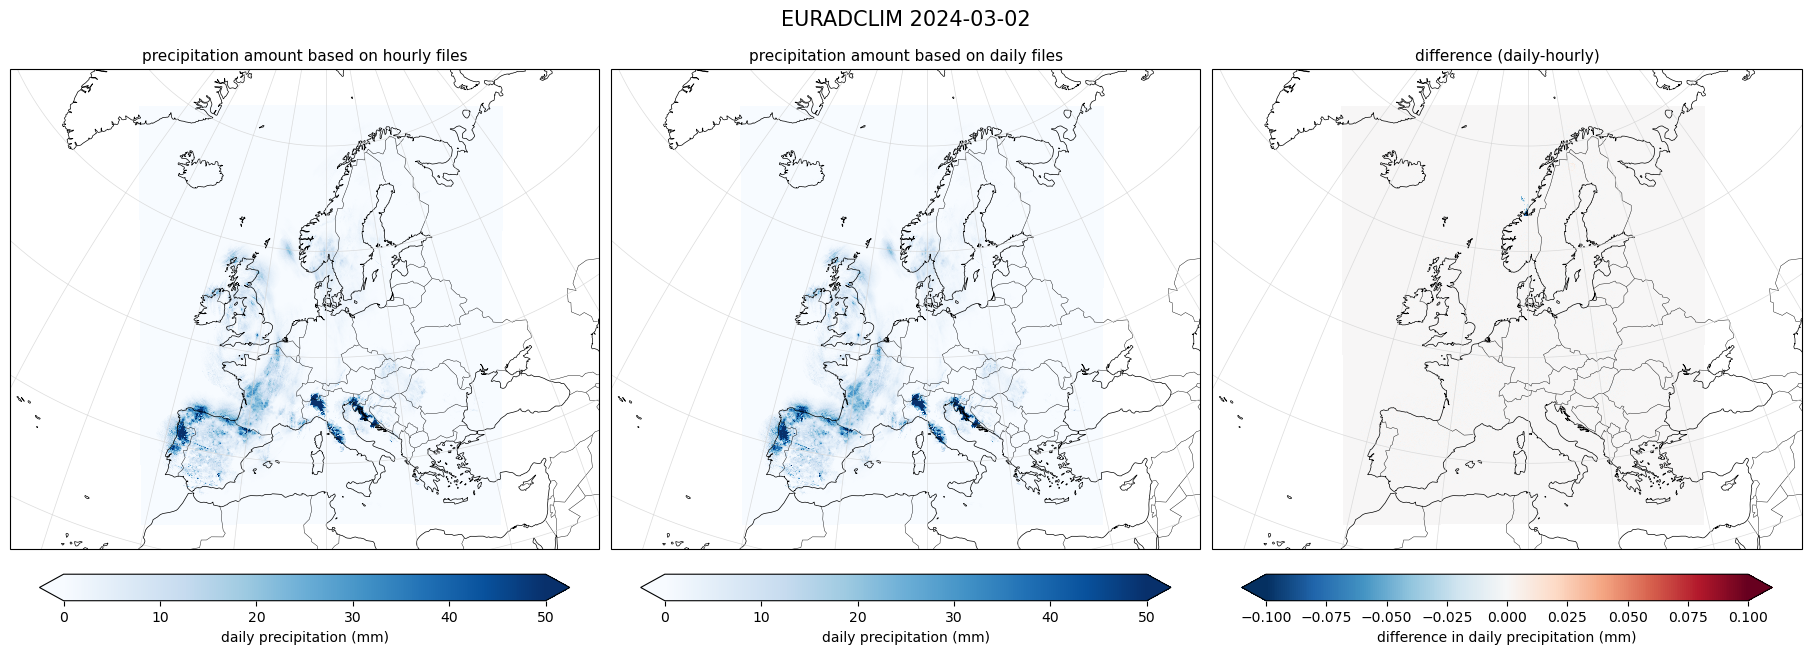

In [20]:
lon2d, lat2d = ds_daily["lon"].values, ds_daily["lat"].values

precip_diff = precip_daily_accumulated-precip_hourly_accumulated
fields = [precip_hourly_accumulated, precip_daily_accumulated,precip_diff]
titles = ["precipitation amount based on hourly files", "precipitation amount based on daily files","difference (daily-hourly)"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6.4), subplot_kw={"projection": ccrs.epsg(3035)}, constrained_layout=True)

for i, (ax, field, title) in enumerate(zip(axes, fields, titles)):
    if i<2:
        mesh = ax.pcolormesh(lon2d, lat2d, field, shading="nearest", transform=ccrs.PlateCarree(),
                         cmap='Blues', vmin=0, vmax=50)
        cbar_label="daily precipitation (mm)"
    else:
        mesh = ax.pcolormesh(lon2d, lat2d, field, shading="nearest", transform=ccrs.PlateCarree(),
                         cmap='RdBu_r', vmin=-0.1, vmax=0.1)
        cbar_label="difference in daily precipitation (mm)"
        
    ax.set_extent([-25, 40, 30, 75], crs=ccrs.PlateCarree())
    ax.coastlines(resolution="50m", linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3)

    # Latitude/longitude grid lines every 10 degrees
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=False, linewidth=0.5,
                      color="lightgrey", alpha=0.8, linestyle="-",
                      xlocs=np.arange(-30, 51, 10), ylocs=np.arange(30, 81, 10))

    ax.set_title(title, fontsize=11)

    cbar = fig.colorbar(mesh, ax=ax, orientation="horizontal", pad=0.04, shrink=0.9, extend="both")
    cbar.set_label(cbar_label)

fig.suptitle("EURADCLIM %s"%(start_of_interval.strftime("%Y-%m-%d")), fontsize=15)
plt.show()

### Deriving time series for stations

A list of European capitals is obtained using cartopy in order to illustrate how to efficiently extract station data from the Xarray datasets.

In [21]:
filename = shpreader.natural_earth(resolution="10m", category="cultural", name="populated_places")

capitals_europe = [(r.attributes["NAME"], r.geometry.x, r.geometry.y)
            for r in shpreader.Reader(filename).records()
            if r.attributes["FEATURECLA"] == "Admin-0 capital"
            and -25 <= r.geometry.x <= 40 and 35 <= r.geometry.y <= 72]

print(capitals_europe[0:5])

[('Vatican City', 12.4533865, 41.9032822), ('San Marino', 12.4417702, 43.9360958), ('Vaduz', 9.5166695, 47.1337238), ('Luxembourg', 6.1300028, 49.6116604), ('Monaco', 7.4069132, 43.7396457)]


The SciPy cKDTree class provides an efficient way to identify the EURADCLIM grid pixel nearest to each station. Distances are calculated after transforming the geographical coordinates into a projected coordinate system.

In [22]:
# EURADCLIM pixel-centre coordinates
lon2d, lat2d = ds_daily["lon"].values, ds_daily["lat"].values

# Transform coordinates to a metric projection
transformer = Transformer.from_crs("EPSG:4326", "EPSG:3035", always_xy=True)
grid_x, grid_y = transformer.transform(lon2d, lat2d)

# Build KD-tree and find nearest pixels
tree = cKDTree(np.column_stack((grid_x.ravel(), grid_y.ravel())))

station_names, station_lon, station_lat = zip(*capitals_europe)
station_x, station_y = transformer.transform(station_lon, station_lat)
distances, indices = tree.query(np.column_stack((station_x, station_y))) # distances refer to the distance of station to the pixel center

# Convert flattened indices to (y, x) indices
iy, ix = np.unravel_index(indices, lon2d.shape)

# Store results
station_pixels = pd.DataFrame({
    "station": station_names,
    "lon": station_lon,
    "lat": station_lat,
    "iy": iy,
    "ix": ix,
    "distance_km": distances / 1000
})
display(station_pixels[0:10])

,station,lon,lat,iy,ix,distance_km
0,Vatican City,12.453387,41.903282,1077,1774,0.897284
1,San Marino,12.441770,43.936096,1073,1662,0.393774
2,Vaduz,9.516670,47.133724,956,1487,0.682647
3,Luxembourg,6.130003,49.611660,835,1345,1.131545
4,Monaco,7.406913,43.739646,870,1673,0.854713
5,Andorra,1.526594,42.510753,625,1722,0.687106
6,Ljubljana,14.514969,46.055288,1150,1541,0.884004
7,Bratislava,17.116981,48.150018,1239,1417,0.557588
8,Podgorica,19.266307,42.465972,1357,1721,0.867041
9,Bern,7.466976,46.916683,878,1497,0.385868


Extracting daily precipitation values for a selected station and visualizing the corresponding 24-hour accumulation intervals:

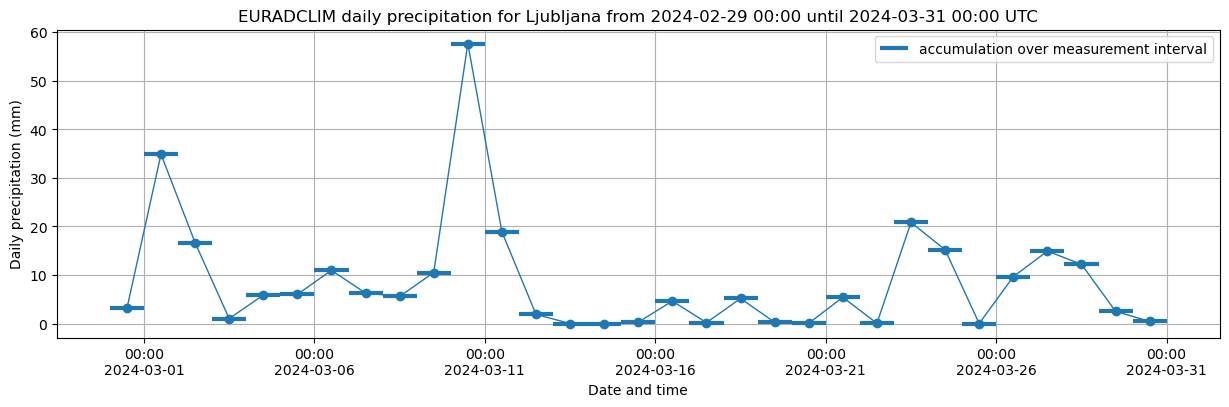

In [23]:
selected_station_name = "Ljubljana"
station = station_pixels.set_index("station").loc[selected_station_name]

# Extract daily precipitation time series
ts_station = ds_daily["precipitation_amount"].isel(y=int(station["iy"]), x=int(station["ix"]))

start_time_string = ds_daily.start_time.values[0].astype("datetime64[us]").astype(datetime).strftime("%Y-%m-%d %H:%M")
end_time_string = ds_daily.end_time.values[-1].astype("datetime64[us]").astype(datetime).strftime("%Y-%m-%d %H:%M UTC")

# Plot time series
fig, ax = plt.subplots(figsize=(15, 4))

# Horizontal lines representing each daily accumulation interval
ax.hlines(y=ts_station.values, xmin=ds_daily.start_time.values, xmax=ds_daily.end_time.values,
          color="C0", linewidth=3, label="accumulation over measurement interval")

# Timeline based on center time of each interval (12h offset applied to start_time)
ax.plot(ds_daily.start_time.values + np.timedelta64(12, "h"), ts_station.values,
        color="C0", marker="o", linewidth=1)

ax.legend()
ax.set_xlabel("Date and time")
ax.set_ylabel("Daily precipitation (mm)")
ax.set_title("EURADCLIM daily precipitation for %s from %s until %s" %
             (selected_station_name, start_time_string, end_time_string))

# Date ticks every 5 days
tick_dates = pd.date_range(start="2024-03-01", end="2024-04-01", freq="5D")
ax.set_xticks(tick_dates)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M\n%Y-%m-%d"))

ax.grid(True)
plt.show()

Extracting precipitation time series for selected locations:

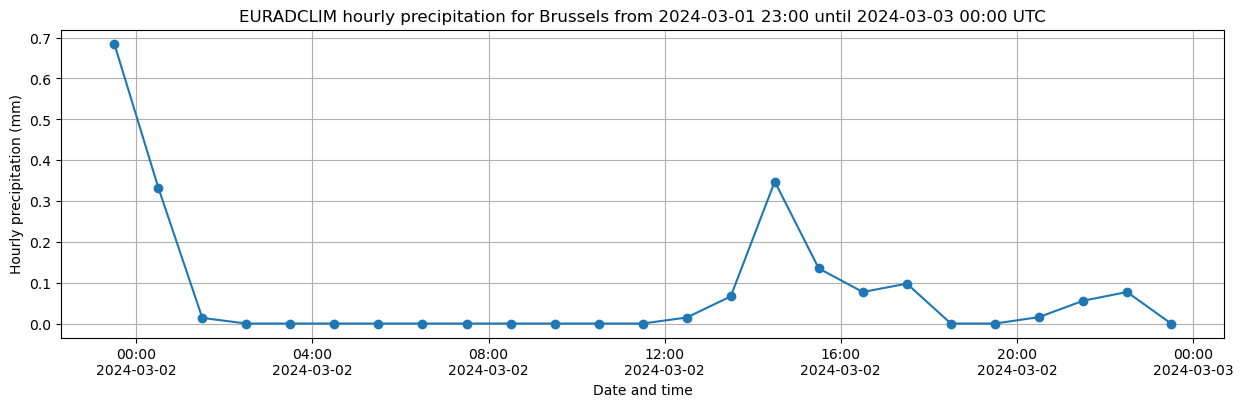

In [24]:
selected_station_name = "Brussels"
station = station_pixels.set_index("station").loc[selected_station_name]

# Extract hourly precipitation time series
ts_station = ds_hourly["precipitation_amount"].isel(y=int(station["iy"]), x=int(station["ix"]))
start_time_string = ds_hourly.start_time.values[0].astype("datetime64[us]").astype(datetime).strftime("%Y-%m-%d %H:%M")
end_time_string = ds_hourly.end_time.values[-1].astype("datetime64[us]").astype(datetime).strftime("%Y-%m-%d %H:%M UTC")

# Plot time series
fig, ax = plt.subplots(figsize=(15, 4))

# plotting of hourly data making use of 30 minute offset to indicate center time of interval
ax.plot(ds_hourly.start_time.values + np.timedelta64(30, "m"),ts_station.values,marker='o')
ax.set_xlabel("Date and time")
ax.set_ylabel("Hourly precipitation (mm)")
ax.set_title("EURADCLIM hourly precipitation for %s from %s until %s"%(selected_station_name, start_time_string, end_time_string))

# Date ticks every 4 hours
tick_dates = pd.date_range(start="2024-03-02", end="2024-03-03", freq="4h")
ax.set_xticks(tick_dates)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M\n%Y-%m-%d"))

ax.grid(True)
plt.show()

## Take home messages 📌


- To download EURADCLIM data automatically from the Climate Data Store (CDS), configure your CDS API credentials.
- EURADCLIM data downloaded from the CDS are provided as ZIP archives containing NetCDF files, which must be extracted before use.
- Xarray provides a convenient way to read and combine multiple EURADCLIM NetCDF files into a single Dataset.
- EURADCLIM uses a structured spatial grid with two-dimensional latitude and longitude coordinates. Understanding this grid structure is important when selecting locations and visualizing the data.
- EURADCLIM timestamps represent the **end of the precipitation accumulation interval**. Correct interpretation of these timestamps is essential when selecting and aggregating hourly and 24-hour precipitation data.

## References


**Datasets**
- Copernicus Climate Change Service, Climate Data Store, (2026): EURADCLIM hourly and daily gridded precipitation data for Europe from 2013 to present derived from radar and rain gauge observations. Copernicus Climate Change Service (C3S) Climate Data Store (CDS). [DOI]( 10.24381/xxxxxxxx)

**Publications**
- Overeem, A., van den Besselaar, E., van der Schrier, G., Meirink, J. F., van der Plas, E., and Leijnse, H. (2023): EURADCLIM: the European climatological high-resolution gauge-adjusted radar precipitation dataset. Earth System Science Data, 15, 1441–1464. [DOI](https://doi.org/10.5194/essd-15-1441-2023)